# Conciliación bancaria automatizada con IA — demo

Este notebook corre el motor completo sobre **un mes de datos sintéticos** (marzo 2026) de una empresa ficticia con dos cuentas bancarias, y mide el resultado contra la respuesta correcta conocida.

**Qué vas a ver:**
1. Extractos de dos bancos con formatos distintos, normalizados y con control de saldos.
2. La conciliación en cascada (5 niveles) contra el libro mayor.
3. Las métricas: % automático, precisión y detección de excepciones.
4. Los pendientes, cada uno con una sugerencia para la revisión humana.
5. Controles de gestión en SQL (DuckDB).

In [1]:
# Preparación: en Colab clona el repositorio; en local usa la carpeta actual
import os, sys
if "google.colab" in sys.modules and not os.path.exists("conciliacion-bancaria-ia"):
    !git clone -q https://github.com/ClaudioCGG/conciliacion-bancaria-ia.git
    !pip install -q rapidfuzz duckdb
if os.path.exists("conciliacion-bancaria-ia"):
    os.chdir("conciliacion-bancaria-ia")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import pandas as pd
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

## 1. Los datos de entrada
Así llega el extracto de **Banco Alfa**: un PDF convertido a Excel, con encabezados repetidos, montos como texto y filas de ruido.

In [2]:
pd.read_excel("data/raw/banco_alfa_202603.xlsx", header=None).head(8)

,0,1,2,3,4,5
0,Banco Alfa S.A. - Resumen de cuenta,NaN,NaN,NaN,NaN,NaN
1,CC $ 0123-004567/8 (Cta.Cte.Bancaria) DISTRIBUIDORA DEL SUR SRL,NaN,NaN,NaN,NaN,NaN
2,"SALDO ANTERIOR 18.452.310,45",NaN,NaN,NaN,NaN,NaN
3,FECHA,CONCEPTO,REFERENCIA,DEBITO,CREDITO,SALDO
4,02/03,TRANSF RECIBIDA GOMEZ LUCIA BEATRIZ CUIT 20-26067314-6 CBU 4529128...,B810014,NaN,"696.938,33","19.149.248,78"
5,02/03,TRANSF RECIBIDA SANCHEZ ROBERTO CARLOS CUIT 20-38514945-9 CBU 4906...,B810016,NaN,"1.301.193,62","20.450.442,40"
6,02/03,TRANSF RECIBIDA TORRES GUSTAVO ADRIAN CUIT 20-13006129-7 CBU 69585...,B810036,NaN,"1.962.926,01","22.413.368,41"
7,02/03,TRANSF RECIBIDA MOLINA FLORENCIA CUIT 20-15711449-9 CBU 4747818244...,B810057,NaN,"1.645.305,48","24.058.673,89"


Después de normalizar, los dos bancos quedan con el mismo esquema, y se verifica fila por fila que el saldo cierre:

In [3]:
from conciliacion.normalizador import normalizar_banco_alfa, normalizar_banco_beta, control_de_saldos

alfa, saldo_alfa = normalizar_banco_alfa("data/raw/banco_alfa_202603.xlsx")
beta, saldo_beta = normalizar_banco_beta("data/raw/banco_beta_202603.xlsx")
print(f"Banco Alfa: {len(alfa)} movimientos | filas que no cierran: {len(control_de_saldos(alfa, saldo_alfa))}")
print(f"Banco Beta: {len(beta)} movimientos | filas que no cierran: {len(control_de_saldos(beta, saldo_beta))}")
alfa.head()

Banco Alfa: 355 movimientos | filas que no cierran: 0
Banco Beta: 58 movimientos | filas que no cierran: 0


,fecha,concepto,ref,ingreso,egreso,saldo,origen,cuenta
0,2026-03-02,TRANSF RECIBIDA GOMEZ LUCIA BEATRIZ CUIT 20-26067314-6 CBU 4529128...,B810014,696938.33,0.0,19149248.78,Banco,Banco Alfa
1,2026-03-02,TRANSF RECIBIDA SANCHEZ ROBERTO CARLOS CUIT 20-38514945-9 CBU 4906...,B810016,1301193.62,0.0,20450442.40,Banco,Banco Alfa
2,2026-03-02,TRANSF RECIBIDA TORRES GUSTAVO ADRIAN CUIT 20-13006129-7 CBU 69585...,B810036,1962926.01,0.0,22413368.41,Banco,Banco Alfa
3,2026-03-02,TRANSF RECIBIDA MOLINA FLORENCIA CUIT 20-15711449-9 CBU 4747818244...,B810057,1645305.48,0.0,24058673.89,Banco,Banco Alfa
4,2026-03-02,TRANSF RECIBIDA FERNANDEZ JUAN PABLO CUIT 20-19006671-8 CBU 514810...,B810078,1124440.97,0.0,25183114.86,Banco,Banco Alfa


## 2. Conciliación
Con `GEMINI_API_KEY` configurada, la etapa de nombres usa Gemini; si no, usa el extractor por reglas (sin costo).

In [4]:
from conciliacion.pipeline import conciliar_periodo

resultados, pendientes, segundos = conciliar_periodo("data/raw", "202603", salida="ejemplos/conciliacion_202603.xlsx")
movimientos = pd.concat([r.movimientos for r in resultados], ignore_index=True)

Extractor de nombres: reglas


Banco Alfa: 554/565 movimientos conciliados (98.1%), 11 pendientes
Banco Beta: 74/74 movimientos conciliados (100.0%), 0 pendientes


Informe: ejemplos/conciliacion_202603.xlsx
Tiempo total: 2.6 s


## 3. ¿Qué tan bien lo hizo?
La métrica crítica es la **precisión**: un falso positivo esconde un error contable.

In [5]:
from conciliacion.metricas import evaluar

verdad = pd.read_csv("data/verdad/verdad_202603.csv")
m = evaluar(movimientos, verdad)
pd.Series({
    "Movimientos": m["movimientos"],
    "Conciliados automáticamente": f"{m['conciliados']} ({m['tasa_automatica']:.1%})",
    "Precisión (lo conciliado estaba bien)": f"{m['precision']:.1%}",
    "Falsos positivos": m["falsos_positivos"],
    "Excepciones sembradas detectadas": f"{m['excepciones_detectadas']} de {m['excepciones']} movimientos",
    "Tiempo": f"{segundos:.1f} s",
}).to_frame("Resultado")

,Resultado
Movimientos,639
Conciliados automáticamente,628 (98.3%)
Precisión (lo conciliado estaba bien),100.0%
Falsos positivos,0
Excepciones sembradas detectadas,9 de 9 movimientos
Tiempo,2.6 s


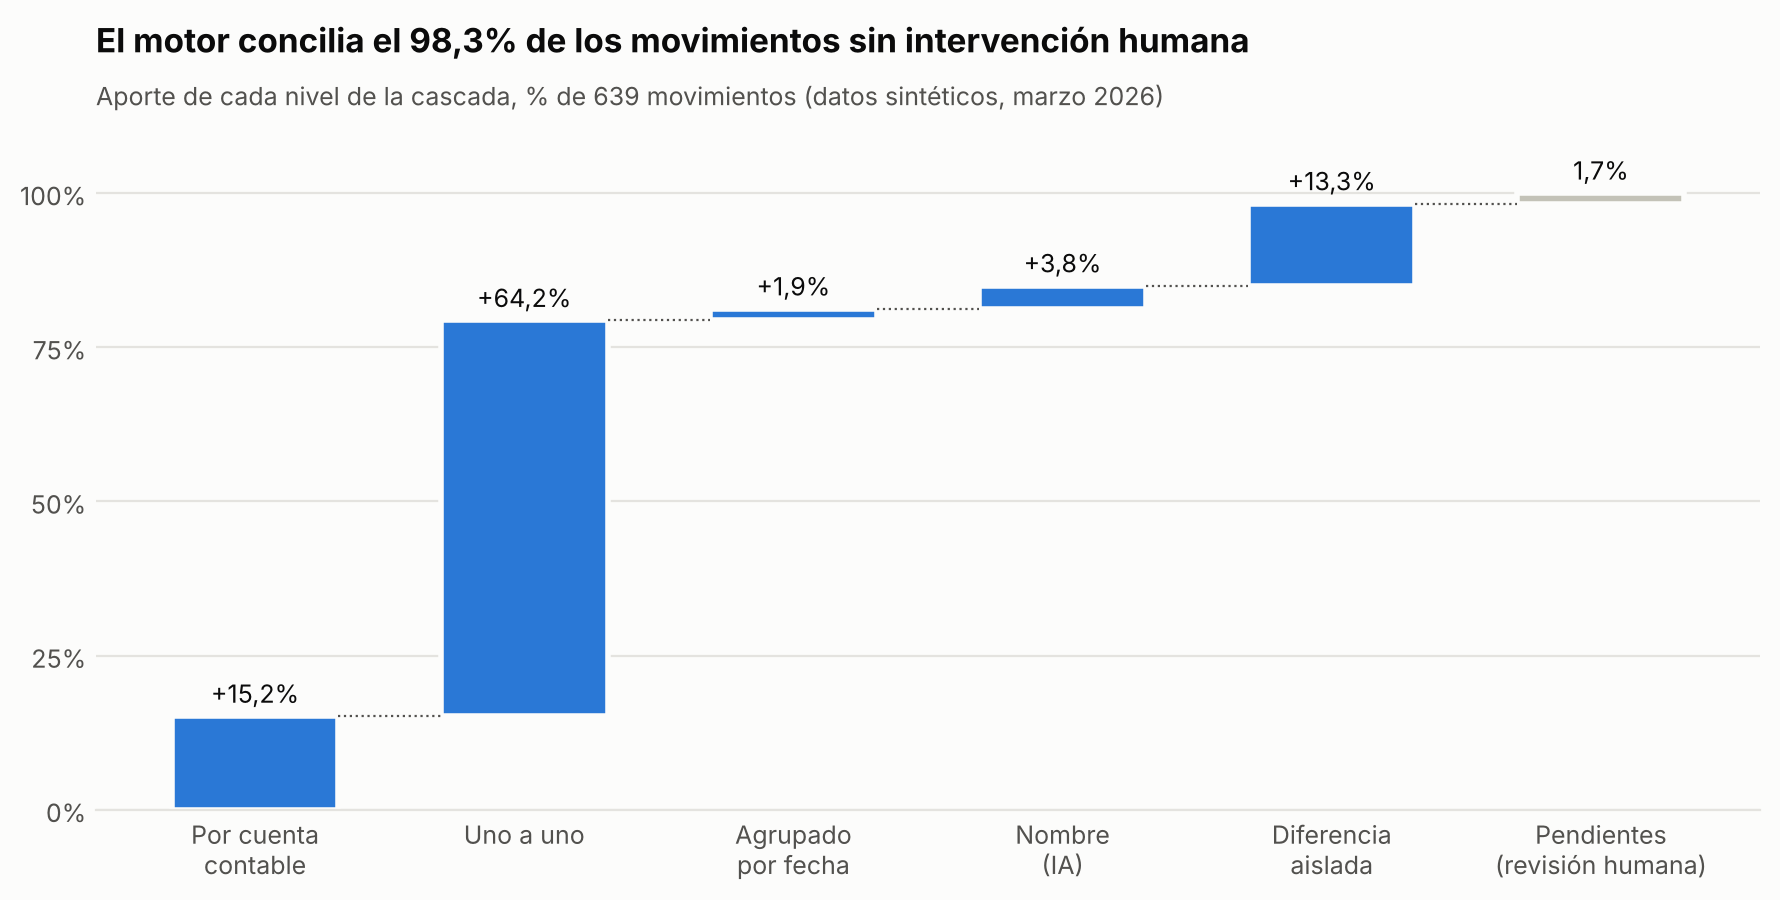

In [6]:
from conciliacion.graficos import grafico_cascada
grafico_cascada(movimientos);

## 4. Pendientes para revisión humana
El motor no fuerza matches dudosos. Cada pendiente sale con una hipótesis de qué pasó.

In [7]:
pendientes[["cuenta", "fecha", "origen", "concepto", "neto", "sugerencia"]].sort_values("fecha")

,cuenta,fecha,origen,concepto,neto,sugerencia
118,Banco Alfa,2026-03-10,Banco,TRANSF RECIBIDA CABRERA JULIETA CUIT 27-29424932-7 CBU 41505017141...,412350.00,Coincide con un asiento que figura duplicado en el mayor: concilia...
419,Banco Alfa,2026-03-10,Contabilidad,Cobro FC A 0001-00001335 Cabrera,412350.00,Posible asiento duplicado (2 asientos iguales). Revisar y anular e...
429,Banco Alfa,2026-03-11,Contabilidad,Cobro FC A 0001-00001335 Cabrera,412350.00,Posible asiento duplicado (2 asientos iguales). Revisar y anular e...
177,Banco Alfa,2026-03-13,Banco,TRANSF RECIBIDA CBU 5540537374002409440741 SIN DATOS ORDENANTE,68316.08,Ingreso sin ordenante identificado. Pedir el comprobante al banco ...
207,Banco Alfa,2026-03-17,Banco,TRANSF RECIBIDA QUIROGA NATALIA CUIT 27-15002743-4 CBU 13248340783...,1250000.00,"Posible error de importe con Quiroga: banco $ 1.250.000,00 vs cont..."
478,Banco Alfa,2026-03-17,Contabilidad,Cobro FC A 0001-00001334 Quiroga,1205000.00,"Posible error de importe con Quiroga: banco $ 1.250.000,00 vs cont..."
303,Banco Alfa,2026-03-25,Banco,ACREDITACION GETNET LIQ 994404,473487.54,Movimiento de 'Tarjetas Getnet' sin asiento. Registrar o justificar.
334,Banco Alfa,2026-03-27,Banco,PAGO HABERES LEGAJO 199 LIQ FINAL,-1900174.61,Movimiento de 'Haberes' sin asiento. Registrar o justificar.
559,Banco Alfa,2026-03-30,Contabilidad,Pago OP 0001-000361 cheque 00045871 Transportes Rioplatense SA,-971894.65,"Posible cheque en tránsito (emitido, aún no debitado). Verificar e..."
353,Banco Alfa,2026-03-31,Banco,COMISION MANTENIMIENTO CUENTA,-18500.00,Movimiento no incluido en el asiento de 'Comisiones y gastos banca...


## 5. Controles de gestión en SQL

In [8]:
import duckdb, re
con = duckdb.connect()
con.register("movimientos", movimientos)
sql = open("sql/controles.sql", encoding="utf-8").read()
consultas = dict(zip(*[iter(re.split(r"^-- name: (\w+)\s*$", sql, flags=re.M)[1:])] * 2))
con.execute(consultas["aporte_por_nivel"]).df()

,nivel,filas,acumulado,pct_acumulado
0,1 · Cuenta contable,97,97.0,15.2
1,2 · Uno a uno,410,507.0,79.3
2,3 · Agrupado por fecha,12,519.0,81.2
3,4 · Nombre (IA),24,543.0,85.0
4,5 · Diferencia aislada,85,628.0,98.3


In [9]:
con.execute(consultas["registros_tardios"]).df()

,cuenta,fecha,concepto,importe,dias_diferencia
0,Banco Alfa,2026-03-27,Cobro FC A 0001-00001322 Gómez,180786.95,18.0
1,Banco Alfa,2026-03-27,Cobro FC A 0001-00001321 Ojeda,345451.28,16.0
2,Banco Alfa,2026-03-17,Cobro FC A 0001-00001320 Ledesma,826453.77,15.0
3,Banco Alfa,2026-03-19,Cobro FC A 0001-00001323 Villalba,315569.64,14.0
4,Banco Alfa,2026-03-20,Cobro FC A 0001-00001319 Ojeda,542342.82,14.0


El informe completo (resumen, pendientes, detalle por banco y por cuenta contable) queda en `ejemplos/conciliacion_202603.xlsx`.